# Ensemble Learning Dashboard

Machine Learning and Pattern Recognition | Student index **224023C**
Compare Random Forest, XGBoost and stacking against the previous bill. Each prediction estimates one monthly bill in kWh for an observed household.

**Data credit**: Algama et al. (2025), [RECON-SL](https://doi.org/10.21227/n1dk-q860), [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Monthly records cover participating LECO households.

**AI assistance**: OpenAI ChatGPT (Codex), 22 November 2026, generated the Python code in all cells, including loading, cleaning, feature construction, models and charts. Record your own observations after running the notebook.

In [1]:
%pip install -q "numpy==2.2.5" "pandas>=2.1,<3" "scikit-learn==1.6.1" "xgboost==2.1.4" "matplotlib>=3.8,<4"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Load and audit the monthly bills
Expected columns are household_Id, month and consumption. Preserve zero bills. Exclude invalid entries and contradictory household-months.

In [2]:
"""AI code credit: OpenAI ChatGPT (Codex), 22 November 2026.
Generated ingestion, feature preparation, chronological evaluation and metrics.
Dataset: Algama et al., RECON-SL, DOI 10.21227/n1dk-q860, CC BY 4.0.
"""
import csv
import io
import math
import re
from collections import Counter
from datetime import date
from statistics import mean

MODELS = ["Last bill", "Random Forest", "XGBoost", "Stacking"]
FEATURES = ["last", "two_back", "three_back", "average", "month_sin", "month_cos"]


def month_number(value):
    # The release documents YYYY-MM. Accept a full ISO date as well.
    match = re.fullmatch(r"(\d{4})[-/](\d{1,2})(?:[-/](\d{1,2}))?", value.strip())
    if not match:
        raise ValueError("Invalid month")
    year, month, day = match.groups()
    parsed = date(int(year), int(month), int(day or 1))
    return parsed.year * 12 + parsed.month - 1


def label(number):
    year, index = divmod(number, 12)
    return f"{year:04d}-{index + 1:02d}"


def read_bills(content):
    reader = csv.DictReader(io.StringIO(content.decode("utf-8-sig")))
    columns = {re.sub(r"[^a-z0-9]", "", key.lower()): key for key in reader.fieldnames or []}
    required = ["householdid", "month", "consumption"]
    if any(key not in columns for key in required):
        raise ValueError(f"Expected household_Id, month, consumption. Found {reader.fieldnames}.")
    bills, conflicts, audit = {}, set(), Counter()
    for row in reader:
        audit["Input rows"] += 1
        household, month, value = [(row.get(columns[key]) or "").strip() for key in required]
        try:
            period = month_number(month)
            units = float(value.replace(",", ""))
            if not household or not math.isfinite(units) or units < 0:
                raise ValueError
        except ValueError:
            audit["Invalid rows skipped"] += 1
            continue
        key = (household, period)
        if key in bills:
            if bills[key] != units:
                conflicts.add(key)
            else:
                audit["Matching duplicate rows"] += 1
        else:
            bills[key] = units
    for key in conflicts:
        del bills[key]
    audit["Conflicting household-months excluded"] = len(conflicts)
    audit["Usable household-months"] = len(bills)
    return bills, dict(audit)

In [3]:
from pathlib import Path
import pandas as pd
paths = [Path("data/monthly_consumption.csv"), Path("../data/monthly_consumption.csv"), Path("monthly_consumption.csv")]
path = next((candidate for candidate in paths if candidate.is_file()), None)
if path is None:
    raise FileNotFoundError("Place data/monthly_consumption.csv in the project or monthly_consumption.csv in the notebook working directory.")
content = path.read_bytes()
bills, audit = read_bills(content)

audit_labels = {
    "Input rows": "Rows read from the CSV",
    "Invalid rows skipped": "Rows skipped because a value was missing or invalid",
    "Matching duplicate rows": "Repeated rows with the same reading",
    "Conflicting household-months excluded": "Household months removed due to conflicting readings",
    "Usable household-months": "Usable monthly bills after cleaning",
}
display(pd.DataFrame([(name, audit.get(key, 0)) for key, name in audit_labels.items()],
                     columns=["Data check", "Count"]).set_index("Data check"))

,Count
Data check,
Rows read from the CSV,101575
Rows skipped because a value was missing or invalid,590
Repeated rows with the same reading,0
Household months removed due to conflicting readings,0
Usable monthly bills after cleaning,100985


## Build one-cycle-ahead examples
The input for each household uses the last three consecutive monthly bills, their average, and the calendar month. The target is the bill for that household in the following month. The code also represents the billing month with two numbers (month_sin and month_cos) so December and January are neighbours in the yearly cycle. The table shows the calendar month directly.

In [4]:
def make_examples(bills):
    rows = []
    for (household, period), actual in sorted(bills.items()):
        history = [bills.get((household, period - offset)) for offset in (1, 2, 3)]
        if None in history:
            continue
        phase = 2 * math.pi * (period % 12) / 12
        rows.append(dict(household=household, period=period, actual=actual,
                         last=history[0], two_back=history[1], three_back=history[2],
                         average=mean(history), month_sin=math.sin(phase), month_cos=math.cos(phase)))
    return rows


def partition(rows):
    periods = sorted({row["period"] for row in rows})
    if len(periods) < 8:
        raise ValueError("Need at least eight eligible target months after forming three consecutive lag months.")
    test_start = periods[-3]
    cal_start = periods[-6]
    fit = [r for r in rows if r["period"] < cal_start]
    cal = [r for r in rows if cal_start <= r["period"] < test_start]
    test = [r for r in rows if r["period"] >= test_start]
    return fit, cal, test

In [5]:
examples = make_examples(bills)
fit, calibration, test = partition(examples)
assert max(r['period'] for r in fit) < min(r['period'] for r in calibration)
assert max(r['period'] for r in calibration) < min(r['period'] for r in test)
print(f"Test bills: {len(test):,}")
print(f"Test households: {len({r['household'] for r in test}):,}")
print(f"Test period: {label(min(r['period'] for r in test))} to {label(max(r['period'] for r in test))}")
print(f"All eligible months: {len(examples):,} bills across {len({r['household'] for r in examples}):,} households")

preview = pd.DataFrame(examples).head().copy()
preview["period"] = preview["period"].map(label)
bill_labels = {"household": "Household ID", "period": "Billing month", "actual": "Recorded usage",
               "last": "1 month earlier", "two_back": "2 months earlier",
               "three_back": "3 months earlier", "average": "3-month average"}
print("Electricity use in kWh. The recorded usage is the value we try to predict.")
display(preview[list(bill_labels)].rename(columns=bill_labels).round(2).set_index(["Household ID", "Billing month"]))

Test bills: 12,056
Test households: 4,028
Test period: 2024-08 to 2024-10
All eligible months: 88,518 bills across 4,063 households
Electricity use in kWh. The recorded usage is the value we try to predict.


Recorded usage  1 month earlier  2 months earlier  \
Household ID Billing month                                                      
ID0001       2023-01                 102.0            129.0             120.0   
             2023-02                 115.0            102.0             129.0   
             2023-03                  97.0            115.0             102.0   
             2023-04                  94.0             97.0             115.0   
             2023-05                  98.0             94.0              97.0   

                            3 months earlier  3-month average  
Household ID Billing month                                     
ID0001       2023-01                   116.0           121.67  
             2023-02                   120.0           117.00  
             2023-03                   129.0           115.33  
             2023-04                   102.0           104.67  
             2023-05                   115.0           102.00

## Train and test the ensembles
Random Forest averages bagged trees. XGBoost adds trees sequentially. Ridge learns how to combine these predictions using a later calibration window. Refit the two base models on all pre-test months. Each test forecast uses the billing history available at that time.

In [6]:
def train_and_test(rows):
    import numpy as np
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.linear_model import Ridge
    from xgboost import XGBRegressor

    def inputs(group):
        return np.array([[r[name] for name in FEATURES] for r in group])

    def train_pair(group):
        x, y = inputs(group), [r["actual"] for r in group]
        forest = RandomForestRegressor(n_estimators=100, max_depth=12, max_features=0.8,
                                       min_samples_leaf=5, n_jobs=2, random_state=42)
        boost = XGBRegressor(n_estimators=150, max_depth=3, learning_rate=0.05,
                             objective="reg:squarederror", tree_method="hist", n_jobs=2, random_state=42)
        return forest.fit(x, y), boost.fit(x, y)

    def predictions(models, group):
        x = inputs(group)
        return np.maximum(0, np.column_stack([model.predict(x) for model in models]))

    fit, cal, test = partition(rows)
    calibration_predictions = predictions(train_pair(fit), cal)
    meta = Ridge(alpha=1.0).fit(calibration_predictions, [r["actual"] for r in cal])
    # Same final base models serve standalone and stacked predictions.
    final_models = train_pair(fit + cal)
    base = predictions(final_models, test)
    stacked = np.maximum(0, meta.predict(base))
    results = []
    for row, (rf, xgb), stack in zip(test, base, stacked):
        values = [row["last"], float(rf), float(xgb), float(stack)]
        results.append({**row, **dict(zip(MODELS, values)), "month": label(row["period"])})
    splits = [{"Stage": name, "First month": label(min(r["period"] for r in group)),
               "Last month": label(max(r["period"] for r in group)), "Bills": len(group)}
              for name, group in zip(["Initial fit", "Stack calibration", "Final test"], (fit, cal, test))]
    importance = dict(zip(FEATURES, map(float, final_models[1].feature_importances_)))
    return results, splits, importance


def scores(results):
    table = []
    actual_mean = mean(row['actual'] for row in results)
    total = sum((row['actual'] - actual_mean) ** 2 for row in results)
    for model in MODELS:
        errors = [row[model] - row["actual"] for row in results]
        table.append({"Model": model, "MAE (kWh)": mean(abs(e) for e in errors),
                      "R2": 1 - sum(e * e for e in errors) / total if total else None,
                      "RMSE (kWh)": math.sqrt(mean(e * e for e in errors))})
    return sorted(table, key=lambda item: item["MAE (kWh)"])



,From month,Through month,Number of bills
Purpose,,,
Train Random Forest and XGBoost,2023-01,2024-04,64392
Learn how to combine their forecasts,2024-05,2024-07,12070
Check forecasts against actual bills,2024-08,2024-10,12056


Lower is better for both errors. Higher is better for R², with 1 meaning a perfect fit.


,"Mean Absolute Error (MAE), kWh","Root Mean Squared Error (RMSE), kWh",Fit score (R²)
Forecast method,,,
Last bill,18.21,49.28,0.86
Random Forest,19.64,47.02,0.87
XGBoost,20.30,52.19,0.85
Stacking,22.51,50.93,0.85


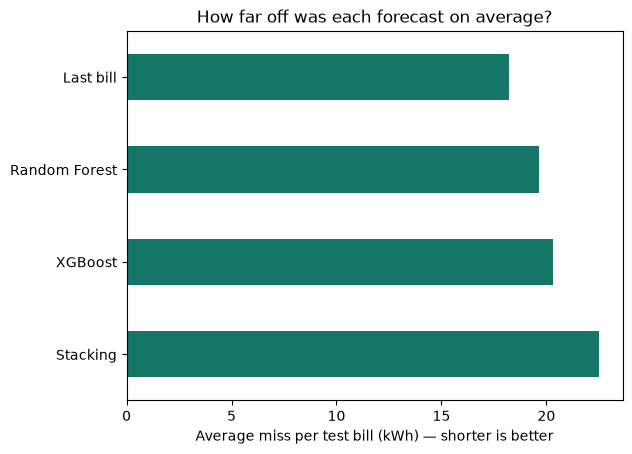

In [7]:
predictions, splits, importance = train_and_test(examples)
results = pd.DataFrame(predictions)
stages = pd.DataFrame(splits)
stages["Stage"] = ["Train Random Forest and XGBoost", "Learn how to combine their forecasts", "Check forecasts against actual bills"]
display(stages.rename(columns={"Stage": "Purpose", "First month": "From month", "Last month": "Through month", "Bills": "Number of bills"}).set_index("Purpose"))
summary = pd.DataFrame(scores(predictions))
score_labels = {"Model": "Forecast method", "MAE (kWh)": "Mean Absolute Error (MAE), kWh",
                "RMSE (kWh)": "Root Mean Squared Error (RMSE), kWh",
                "R2": "Fit score (R²)"}
print("Lower is better for both errors. Higher is better for R², with 1 meaning a perfect fit.")
display(summary[list(score_labels)].rename(columns=score_labels).round(2).set_index("Forecast method"))
ax = summary.set_index("Model")["MAE (kWh)"].plot.barh(color="#157567", title="How far off was each forecast on average?")
ax.set_xlabel("Average miss per test bill (kWh) — shorter is better")
ax.set_ylabel("")
ax.invert_yaxis()

## Examine individual bills and monthly differences

In [8]:
errors = results[MODELS].sub(results.actual, axis=0).abs()
print("Average forecast error by test month (kWh). Smaller values are better.")
display(errors.groupby(results.month).mean().round(2).rename_axis("Test month"))
household = results.household.iloc[0]  # Choose another household ID to explore.
print(f"Recorded and predicted electricity use for {household} (kWh)")
selected = results.loc[results.household.eq(household), ["month", "actual"] + MODELS]
display(selected.rename(columns={"month": "Billing month", "actual": "Recorded usage",
    "Last bill": "Forecast from previous bill", "Random Forest": "Random Forest forecast",
    "XGBoost": "XGBoost forecast", "Stacking": "Stacking forecast"}).round(2).set_index("Billing month"))

Average forecast error by test month (kWh). Smaller values are better.


,Last bill,Random Forest,XGBoost,Stacking
Test month,,,,
2024-08,17.84,17.69,18.45,20.51
2024-09,18.04,17.69,18.49,19.68
2024-10,18.75,23.53,23.96,27.34


Recorded and predicted electricity use for ID0001 (kWh)


,Recorded usage,Forecast from previous bill,Random Forest forecast,XGBoost forecast,Stacking forecast
Billing month,,,,,
2024-08,76.0,73.0,76.09,77.89,76.03
2024-09,79.0,76.0,78.36,76.98,78.01
2024-10,107.0,79.0,75.44,73.61,75.36


## Your interpretation
1. Which method had the smallest mean absolute error (MAE)? By how many kWh did it improve on the previous-bill baseline, or fall behind it?
2. Did stacking improve on both base models? Was its ranking consistent across test months?
3. Choose one bill, calculate its absolute error, and compare this example with overall MAE.
4. What can the selected test months and LECO service area tell you about generalisation?